# Étape 7 : Politique de priorisation et valeur métier

**Client :** NASA/JPL Planetary Defense Coordination Office (PDCO)
**Pilier évalué :** n° 4, *business value translation*, avec des seuils chiffrés.

### Ce qu'on construit

Une **file de priorité** qui dit, pour chaque objet du catalogue, **quand l'observer** :

| Niveau | Décision |
|---|---|
| **Niveau 1** | Observer **ce cycle** |
| **Niveau 2** | Observer **au prochain cycle** |
| **Niveau 3** | **Surveillance passive** par les relevés automatiques |

### Ce qu'on combine

| Brique | Origine | Rôle dans la décision |
|---|---|---|
| MOID | Catalogue (mesure officielle) | L'orbite peut-elle passer près de la Terre ? |
| Diamètre estimé et **borne haute** | Étape 4 (régression) | L'objet est-il assez gros ? Version prudente pour le « zéro faux négatif » |
| Énergie d'impact pessimiste | Calculée à partir de l'étape 4 | Gravité, pour ordonner la file |
| Probabilité PHA | Étape 5 (classification) | Filet de sécurité quand le MOID n'est pas encore fiable (objets tout juste découverts) |
| Cluster | Étape 6 | Regrouper les observations en campagnes |
| Approches 2026–2035, incertitude de l'orbite, date de découverte | Catalogue et fichier d'approches | **Urgence** |

Ici, le MOID et H **peuvent** être utilisés : on ne cherche plus à évaluer un modèle, mais à prendre une décision avec toute l'information disponible. La fuite de données ne concernait que l'entraînement et l'évaluation de l'étape 5.

Exécutez les notebooks 03 à 06 avant celui-ci.

## 1. Paramètres de la politique

Tous les seuils sont regroupés ici, avec leur justification. Pour tester une autre politique, il suffit de les modifier et de relancer le notebook.

In [1]:
# --- Seuils de risque -------------------------------------------------------
MOID_MAX_AU = 0.05            # définition officielle d'un PHA (CNEOS)
DIAMETRE_MIN_KM = 0.14        # 140 m : seuil de dégâts régionaux (définition PHA, objectif du Congrès US)
APPROCHE_URGENTE_DL = 20      # approche future à moins de 20 distances lunaires (≈ 0,05 UA) d'ici 2035
CONDITION_CODE_INCERTAIN = 7  # incertitude d'orbite JPL de 0 (excellente) à 9 (très mauvaise)
DECOUVERTE_RECENTE_JOURS = 365  # découvert dans l'année précédant l'extraction des données

# --- Hypothèses physiques pour l'énergie -----------------------------------
DENSITE_KG_M3 = 2600          # densité moyenne d'un astéroïde rocheux (hypothèse)
VITESSE_LIBERATION_KMS = 11.2 # vitesse ajoutée par l'attraction terrestre à l'impact
MT_TNT_J = 4.184e15           # 1 mégatonne de TNT en joules

# --- Hypothèses de coût (illustratives, à remplacer par les données réelles de la PDCO)
OBS_PAR_AN = {"Niveau 1": 4, "Niveau 2": 1, "Niveau 3": 0}   # observations dédiées par objet et par an
HEURES_PAR_OBSERVATION = 1.0
COUT_HEURE_USD = 5_000

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_columns", 30)

def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Dossier nasa-project/data/raw introuvable.")

PROJECT_DIR = find_project_dir()
RAW_DIR = PROJECT_DIR / "data" / "raw"
P = PROJECT_DIR / "data" / "processed"
INPUTS = {
    "diamètres (étape 4)": P / "04_diameter" / "catalogue_diametres.csv",
    "scores PHA (étape 5)": P / "05_classification" / "scores_catalogue.csv",
    "clusters (étape 6)": P / "06_clustering" / "clusters_catalogue.csv",
}
for name, f in INPUTS.items():
    if not f.exists():
        raise FileNotFoundError(f"Fichier manquant : {name}. Exécutez les notebooks 03 à 06.")
PROCESSED_DIR = P / "07_risk_policy"
REPORT_DIR = PROJECT_DIR / "reports" / "07_risk_policy"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

seuils_etape5 = pd.read_json(PROJECT_DIR / "reports" / "05_classification" / "seuils.json", typ="series")

TIER_COLORS = {"Niveau 1": "#C0392B", "Niveau 2": "#E07A2D", "Niveau 3": "#8C8C8C"}
BLUE, GREY, RED = "#2878B5", "#8C8C8C", "#C0392B"
LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}".replace(",", " ")

## 2. Assembler toutes les briques

In [3]:
asteroids = pd.read_csv(sorted(RAW_DIR.glob("near_earth_asteroids_2025*.csv"))[0], low_memory=False)
approaches = pd.read_csv(sorted(RAW_DIR.glob("asteroid_close_approaches_2015_2035*.csv"))[0], low_memory=False)
approaches["date"] = pd.to_datetime(approaches["close_approach_date"])
EXTRACTION = approaches.loc[approaches["is_future"], "date"].min().normalize()
print(f"Date d'extraction des données : {EXTRACTION:%d/%m/%Y}")

# Prochaine approche future (après l'extraction) la plus proche, par objet
future = approaches[approaches["is_future"]].sort_values("dist_lunar")
next_app = (future.groupby("designation").first()[["dist_lunar", "date"]]
            .rename(columns={"dist_lunar": "approche_min_DL", "date": "date_approche_min"}))
# Vitesse d'arrivée typique de l'objet (toutes ses approches connues)
vinf = approaches.groupby("designation")["velocity_infinity_km_s"].median().rename("v_inf_kms")

df = (asteroids[["pdes", "full_name", "pha", "H", "moid_au", "condition_code", "first_obs", "class"]]
      .merge(pd.read_csv(INPUTS["diamètres (étape 4)"])[["pdes", "diametre_km", "diametre_km_bas", "diametre_km_haut", "source_diametre", "hors_domaine"]], on="pdes", how="left")
      .merge(pd.read_csv(INPUTS["scores PHA (étape 5)"])[["pdes", "proba_pha", "signale"]], on="pdes", how="left")
      .merge(pd.read_csv(INPUTS["clusters (étape 6)"])[["pdes", "cluster"]], on="pdes", how="left")
      .merge(next_app, left_on="pdes", right_index=True, how="left")
      .merge(vinf, left_on="pdes", right_index=True, how="left"))
df["full_name"] = df["full_name"].str.strip()
df["first_obs"] = pd.to_datetime(df["first_obs"], errors="coerce")
print(f"{fmt(len(df))} objets, dont {fmt(df['approche_min_DL'].notna().sum())} avec une approche prévue d'ici 2035")

Date d'extraction des données : 25/03/2026


41 281 objets, dont 3 289 avec une approche prévue d'ici 2035


## 3. Gravité : énergie d'impact pessimiste

L'énergie cinétique d'un impact vaut ½ m v². On l'estime pour chaque objet :

- **masse** = densité × volume d'une sphère de diamètre D. On prend la **borne haute** du diamètre (étape 4), pour la version prudente ;
- **vitesse d'impact** = √(v∞² + 11,2²) km/s, où v∞ est la vitesse d'arrivée de l'objet (médiane de ses approches connues, ou médiane du catalogue s'il n'en a pas), et 11,2 km/s l'accélération due à l'attraction terrestre.

L'énergie est exprimée en **mégatonnes de TNT**. Repères : Tcheliabinsk (2013, ~20 m) ≈ 0,5 Mt ; Toungouska (1908, ~50 m) ≈ 10 Mt ; un objet de 140 m ≈ 100 Mt.

In [4]:
v_inf = df["v_inf_kms"].fillna(approaches["velocity_infinity_km_s"].median())
v_impact_ms = np.sqrt(v_inf ** 2 + VITESSE_LIBERATION_KMS ** 2) * 1e3

def energy_mt(diameter_km):
    mass = DENSITE_KG_M3 * np.pi / 6 * (diameter_km * 1e3) ** 3
    return 0.5 * mass * v_impact_ms ** 2 / MT_TNT_J

df["energie_Mt"] = energy_mt(df["diametre_km"])
df["energie_Mt_haute"] = energy_mt(df["diametre_km_haut"])

ratio = (df["energie_Mt_haute"] / df["energie_Mt"]).where(df["source_diametre"] == "prédit")
print(f"Pour un diamètre prédit, l'énergie pessimiste vaut ×{ratio.median():.1f} l'énergie estimée "
      f"(le diamètre est au cube).")
df[["diametre_km", "diametre_km_haut", "energie_Mt", "energie_Mt_haute"]].describe(percentiles=[0.5, 0.9, 0.99]).T

Pour un diamètre prédit, l'énergie pessimiste vaut ×9.8 l'énergie estimée (le diamètre est au cube).


,count,mean,std,min,50%,90%,99%,max
diametre_km,"41,281.000",0.199,0.430,0.000,0.062,0.519,1.665,37.675
diametre_km_haut,"41,281.000",0.390,0.683,0.001,0.132,1.045,3.092,37.675
energie_Mt,"41,281.000","71,100.636","9,350,739.237",0.000,9.794,"5,320.445","177,230.368","1,875,395,264.070"
energie_Mt_haute,"41,281.000","120,553.638","9,381,613.554",0.000,93.552,"42,651.421","1,078,665.997","1,875,395,264.070"


## 4. Les règles de décision

**Étape A : le risque.** Deux catégories, selon la taille :

- **PHA probable** : MOID ≤ 0,05 UA **et** diamètre **estimé** ≥ 140 m ;
- **PHA possible** : MOID ≤ 0,05 UA, diamètre estimé < 140 m, mais **borne haute** ≥ 140 m. L'objet pourrait être dangereux s'il est plus sombre que prévu.

**Étape B : l'urgence.** Un objet est urgent si au moins une condition est remplie :

- **approche proche** : passage prévu à moins de 20 distances lunaires d'ici 2035 ;
- **orbite incertaine** : `condition_code` ≥ 7, risque de « perdre » l'objet faute d'observations ;
- **découverte récente** : moins d'un an avant l'extraction ; son MOID et sa taille sont encore peu fiables.

**Étape C : le niveau.**

| Niveau | Règle |
|---|---|
| **Niveau 1** | PHA probable **et** urgent |
| **Niveau 2** | PHA probable non urgent, **ou** PHA possible, **ou** découverte récente signalée par le modèle de l'étape 5 avec une borne haute ≥ 140 m |
| **Niveau 3** | Tout le reste |

Le dernier critère du niveau 2 est le **filet de sécurité** du modèle de l'étape 5 : pour un objet tout juste découvert, le MOID peut encore changer beaucoup ; si le modèle juge son profil dangereux, on ne l'abandonne pas aux relevés passifs.

In [5]:
proche_orbite = df["moid_au"] <= MOID_MAX_AU
probable = proche_orbite & (df["diametre_km"] >= DIAMETRE_MIN_KM)
possible = proche_orbite & ~probable & (df["diametre_km_haut"] >= DIAMETRE_MIN_KM)

approche_proche = df["approche_min_DL"] < APPROCHE_URGENTE_DL
orbite_incertaine = df["condition_code"] >= CONDITION_CODE_INCERTAIN
decouverte_recente = df["first_obs"] >= EXTRACTION - pd.Timedelta(days=DECOUVERTE_RECENTE_JOURS)
urgent = approche_proche | orbite_incertaine | decouverte_recente
filet_modele = decouverte_recente & df["signale"].fillna(False).astype(bool) & (df["diametre_km_haut"] >= DIAMETRE_MIN_KM)

niveau1 = probable & urgent
niveau2 = ~niveau1 & (probable | possible | filet_modele)
df["niveau"] = np.select([niveau1, niveau2], ["Niveau 1", "Niveau 2"], default="Niveau 3")
df["categorie_risque"] = np.select([probable, possible], ["PHA probable", "PHA possible"], default="—")

def reasons(i):
    r = []
    if probable[i]: r.append("PHA probable")
    if possible[i]: r.append("PHA possible (borne haute)")
    if approche_proche[i]: r.append(f"approche à {df.at[i, 'approche_min_DL']:.1f} DL")
    if orbite_incertaine[i]: r.append(f"orbite incertaine (code {int(df.at[i, 'condition_code'])})")
    if decouverte_recente[i]: r.append("découverte récente")
    if filet_modele[i] and not (probable[i] or possible[i]): r.append("signalé par le modèle (étape 5)")
    return " · ".join(r)

df["raisons"] = [reasons(i) for i in df.index]

summary = df.groupby("niveau").agg(
    objets=("pdes", "size"),
    PHA_officiels=("pha", "sum"),
    energie_haute_mediane_Mt=("energie_Mt_haute", "median"),
)
summary["part_catalogue_%"] = summary["objets"] / len(df) * 100
summary["part_des_PHA_officiels_%"] = summary["PHA_officiels"] / df["pha"].sum() * 100
summary.to_csv(REPORT_DIR / "synthese_niveaux.csv")
summary

,objets,PHA_officiels,energie_haute_mediane_Mt,part_catalogue_%,part_des_PHA_officiels_%
niveau,,,,,
Niveau 1,730,429,"3,358.529",1.768,16.896
Niveau 2,4880,2098,"1,349.212",11.821,82.631
Niveau 3,35671,12,42.769,86.410,0.473


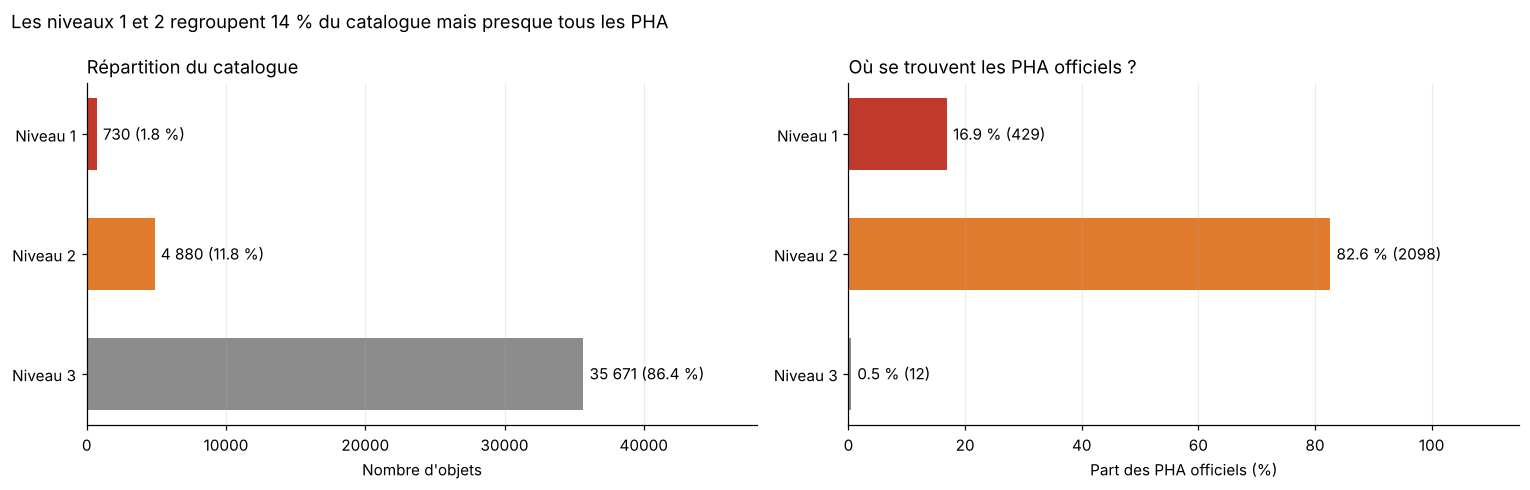

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
tiers = ["Niveau 1", "Niveau 2", "Niveau 3"]
ax = axes[0]
bars = ax.barh(tiers[::-1], summary.loc[tiers[::-1], "objets"], color=[TIER_COLORS[t] for t in tiers[::-1]], height=0.6)
ax.bar_label(bars, labels=[f"{fmt(n)} ({p:.1f} %)" for n, p in zip(summary.loc[tiers[::-1], "objets"], summary.loc[tiers[::-1], "part_catalogue_%"])], padding=4)
ax.set_xlim(0, summary["objets"].max() * 1.35)
ax.set_xlabel("Nombre d'objets")
ax.set_title("Répartition du catalogue", loc="left")
ax.grid(axis="y", visible=False)

ax = axes[1]
bars = ax.barh(tiers[::-1], summary.loc[tiers[::-1], "part_des_PHA_officiels_%"], color=[TIER_COLORS[t] for t in tiers[::-1]], height=0.6)
ax.bar_label(bars, labels=[f"{p:.1f} % ({int(n)})" for p, n in zip(summary.loc[tiers[::-1], "part_des_PHA_officiels_%"], summary.loc[tiers[::-1], "PHA_officiels"])], padding=4)
ax.set_xlim(0, 115)
ax.set_xlabel("Part des PHA officiels (%)")
ax.set_title("Où se trouvent les PHA officiels ?", loc="left")
ax.grid(axis="y", visible=False)
active = summary.loc[["Niveau 1", "Niveau 2"], "part_catalogue_%"].sum()
fig.suptitle(f"Les niveaux 1 et 2 regroupent {active:.0f} % du catalogue mais presque tous les PHA", x=0.01, ha="left")
fig.tight_layout()
save(fig, "repartition_niveaux")
plt.show()

## 5. Vérification : la politique respecte-t-elle le « zéro faux négatif » ?

On utilise maintenant le label officiel `pha` **pour contrôler** la politique : combien de PHA officiels finissent en niveau 3 ?

In [7]:
missed = df[(df["niveau"] == "Niveau 3") & df["pha"]]
rappel = 1 - len(missed) / df["pha"].sum()
print(f"PHA officiels en niveau 1 ou 2 : {rappel:.2%} ({fmt(df['pha'].sum() - len(missed))} sur {fmt(df['pha'].sum())})")
print(f"PHA officiels en niveau 3 : {len(missed)}")
print("Source du diamètre de ces objets :", missed["source_diametre"].value_counts().to_dict())
missed[["pdes", "H", "moid_au", "source_diametre", "diametre_km", "diametre_km_haut"]].sort_values("diametre_km")

PHA officiels en niveau 1 ou 2 : 99.53% (2 527 sur 2 539)
PHA officiels en niveau 3 : 12
Source du diamètre de ces objets : {'mesuré': 12}


,pdes,H,moid_au,source_diametre,diametre_km,diametre_km_haut
13576,2015 TK238,21.900,0.014,mesuré,0.076,0.076
2688,518810,21.850,0.032,mesuré,0.083,0.083
625,154590,21.700,0.013,mesuré,0.086,0.086
7843,2010 FF10,21.800,0.037,mesuré,0.095,0.095
7981,2010 LK34,21.910,0.009,mesuré,0.108,0.108
11085,2014 BX2,21.890,0.004,mesuré,0.110,0.110
1063,264357,21.170,0.021,mesuré,0.113,0.113
14162,2016 CL136,21.300,0.028,mesuré,0.123,0.123
3711,877685,21.550,0.014,mesuré,0.124,0.124
7225,2009 FY4,21.000,0.043,mesuré,0.129,0.129


**Lecture :** les rares PHA officiels laissés en niveau 3 ont bien un MOID ≤ 0,05 UA, mais leur diamètre a été **réellement mesuré** et il est **inférieur à 140 m**. La liste officielle les classe PHA parce que leur H est inférieur à 22, ce qui suppose un albédo de 0,14 ; leur taille mesurée montre qu'ils sont en fait plus clairs, donc plus petits. La politique s'appuie sur la mesure plutôt que sur l'approximation. C'est un choix assumé, à signaler à la PDCO : si elle préfère suivre la liste officielle à la lettre, il suffit d'ajouter la condition `pha == True` au niveau 2.

**Ce que la politique ajoute à la liste officielle :**

In [8]:
hidden = df[probable & ~df["pha"]]
possible_only = df[possible & ~df["pha"]]
added = pd.DataFrame({
    "catégorie": [
        "PHA probables absents de la liste officielle",
        "PHA possibles (borne haute ≥ 140 m) absents de la liste officielle",
        "Découvertes récentes signalées par le modèle, hors PHA probables ou possibles",
    ],
    "objets": [
        len(hidden),
        len(possible_only),
        int((filet_modele & ~probable & ~possible).sum()),
    ],
})
added.to_csv(REPORT_DIR / "ajouts_vs_liste_officielle.csv", index=False)
added

,catégorie,objets
0,PHA probables absents de la liste officielle,662
1,PHA possibles (borne haute ≥ 140 m) absents de...,2184
2,"Découvertes récentes signalées par le modèle, ...",237


Ces objets ont H > 22 : ils n'apparaissent pas dans la liste officielle, qui suppose un albédo de 0,14. Mais le modèle de l'étape 4 les estime plus sombres, donc plus gros que 140 m (« probables »), ou ne peut pas exclure qu'ils le soient (« possibles »). Pour une politique « zéro faux négatif », ils méritent d'être suivis.

## 6. Visualiser la politique

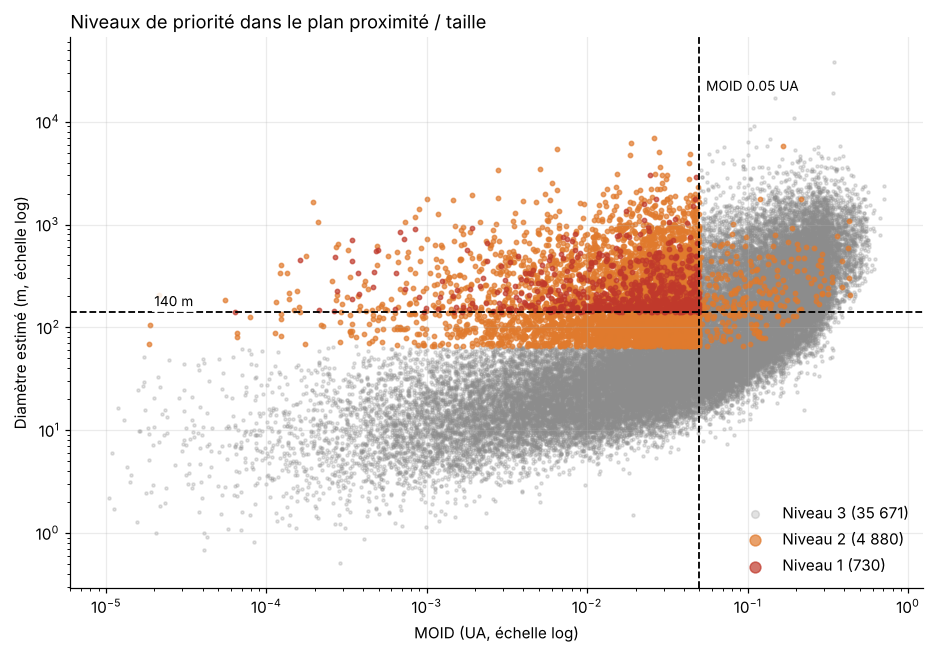

In [9]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for tier in ["Niveau 3", "Niveau 2", "Niveau 1"]:
    d = df[df["niveau"] == tier]
    ax.scatter(d["moid_au"] + 1e-5, d["diametre_km"] * 1000, s=4 if tier == "Niveau 3" else 8,
               alpha=0.25 if tier == "Niveau 3" else 0.7, color=TIER_COLORS[tier],
               label=f"{tier} ({fmt(len(d))})", rasterized=True)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(MOID_MAX_AU, color="black", ls="--", lw=1.2)
ax.axhline(DIAMETRE_MIN_KM * 1000, color="black", ls="--", lw=1.2)
ax.text(MOID_MAX_AU * 1.1, 2e4, f"MOID {MOID_MAX_AU} UA", fontsize=9, bbox=LABEL_BOX)
ax.text(2e-5, DIAMETRE_MIN_KM * 1000 * 1.15, "140 m", fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("MOID (UA, échelle log)")
ax.set_ylabel("Diamètre estimé (m, échelle log)")
ax.set_title("Niveaux de priorité dans le plan proximité / taille", loc="left")
ax.legend(frameon=False, markerscale=2.5, loc="lower right")
save(fig, "niveaux_moid_diametre")
plt.show()

**Lecture :** le niveau 1 occupe le coin « proche et gros ». Le niveau 2 déborde **sous** la ligne des 140 m : ce sont les PHA possibles, dont le diamètre estimé est inférieur à 140 m mais dont la borne haute la dépasse. C'est la marge de sécurité apportée par l'intervalle de l'étape 4. Les quelques points orange **à droite** de la ligne MOID sont les découvertes récentes rattrapées par le modèle de l'étape 5 : leur MOID actuel dépasse 0,05 UA, mais il est encore peu fiable.

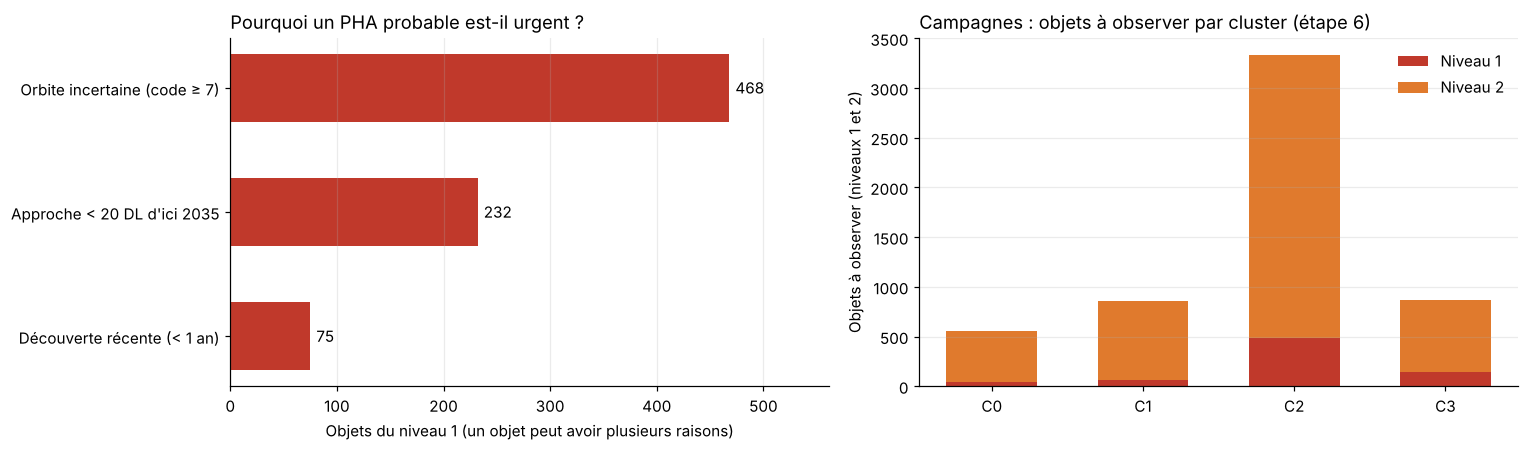

niveau,Niveau 1,Niveau 2,Niveau 3
cluster,,,
0.000,39,512,10451
1.000,62,793,9990
2.000,490,2847,9951
3.000,139,728,5148


In [10]:
n1 = df[df["niveau"] == "Niveau 1"]
reason_counts = pd.Series({
    "Approche < 20 DL d'ici 2035": approche_proche[n1.index].sum(),
    "Orbite incertaine (code ≥ 7)": orbite_incertaine[n1.index].sum(),
    "Découverte récente (< 1 an)": decouverte_recente[n1.index].sum(),
}).sort_values()
cross = pd.crosstab(df["cluster"], df["niveau"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
bars = ax.barh(reason_counts.index, reason_counts.values, color=TIER_COLORS["Niveau 1"], height=0.55)
ax.bar_label(bars, labels=[fmt(v) for v in reason_counts.values], padding=4)
ax.set_xlim(0, reason_counts.max() * 1.2)
ax.set_xlabel("Objets du niveau 1 (un objet peut avoir plusieurs raisons)")
ax.set_title("Pourquoi un PHA probable est-il urgent ?", loc="left")
ax.grid(axis="y", visible=False)

ax = axes[1]
bottom = np.zeros(len(cross))
for tier in ["Niveau 1", "Niveau 2"]:
    vals = cross.get(tier, pd.Series(0, index=cross.index)).to_numpy()
    ax.bar([f"C{int(c)}" for c in cross.index], vals, bottom=bottom, color=TIER_COLORS[tier], label=tier, width=0.6)
    bottom += vals
ax.set_ylabel("Objets à observer (niveaux 1 et 2)")
ax.set_title("Campagnes : objets à observer par cluster (étape 6)", loc="left")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "raisons_et_clusters")
plt.show()
cross

## 7. Valeur métier : temps de télescope

On compare le temps d'observation dédié nécessaire chaque année selon quatre politiques, avec les **mêmes hypothèses** (section 1) : un objet suivi de près est observé 4 fois par an, un objet suivi normalement 1 fois par an, à raison d'une heure par observation.

| Politique | Qui est observé, et à quelle fréquence |
|---|---|
| Tout surveiller | Tout le catalogue, 1 fois par an |
| Règle « l'orbite croise celle de la Terre » | 73 % du catalogue (étape 5), 1 fois par an |
| Liste PHA officielle | Les 2 539 PHA, 2 fois par an, sans distinction d'urgence |
| **Notre politique** | Niveau 1 : 4 fois par an ; niveau 2 : 1 fois par an ; niveau 3 : relevés passifs |

**Les coûts sont des hypothèses illustratives**, à remplacer par les vrais coûts d'observation de la PDCO. Ce qui compte, c'est la comparaison entre politiques, qui ne dépend pas du coût horaire.

In [11]:
rule = ((asteroids["q"] <= 1.05) & (asteroids["ad"] >= 0.95))
h = HEURES_PAR_OBSERVATION
policies = pd.DataFrame([
    {"politique": "Tout surveiller", "objets suivis": len(df), "heures / an": len(df) * 1 * h,
     "PHA officiels couverts": df["pha"].sum(), "objets au-delà de la liste officielle": int((~df["pha"]).sum())},
    {"politique": "Règle « croise l'orbite terrestre »", "objets suivis": int(rule.sum()), "heures / an": rule.sum() * 1 * h,
     "PHA officiels couverts": int(df.loc[rule.to_numpy(), "pha"].sum()), "objets au-delà de la liste officielle": int((rule.to_numpy() & ~df["pha"]).sum())},
    {"politique": "Liste PHA officielle", "objets suivis": int(df["pha"].sum()), "heures / an": df["pha"].sum() * 2 * h,
     "PHA officiels couverts": int(df["pha"].sum()), "objets au-delà de la liste officielle": 0},
    {"politique": "Notre politique", "objets suivis": int((df["niveau"] != "Niveau 3").sum()),
     "heures / an": sum(OBS_PAR_AN[t] * (df["niveau"] == t).sum() for t in OBS_PAR_AN) * h,
     "PHA officiels couverts": int(df.loc[df["niveau"] != "Niveau 3", "pha"].sum()),
     "objets au-delà de la liste officielle": int(((df["niveau"] != "Niveau 3") & ~df["pha"]).sum())},
]).set_index("politique")
policies["coût annuel (M$, hypothèse)"] = policies["heures / an"] * COUT_HEURE_USD / 1e6
policies["% des PHA officiels"] = policies["PHA officiels couverts"] / df["pha"].sum() * 100
policies.to_csv(REPORT_DIR / "comparaison_politiques.csv")
policies.round(1)

,objets suivis,heures / an,PHA officiels couverts,objets au-delà de la liste officielle,"coût annuel (M$, hypothèse)",% des PHA officiels
politique,,,,,,
Tout surveiller,41281,"41,281.000",2539,38742,206.400,100.000
Règle « croise l'orbite terrestre »,30348,"30,348.000",2523,27825,151.700,99.400
Liste PHA officielle,2539,"5,078.000",2539,0,25.400,100.000
Notre politique,5610,"7,800.000",2527,3083,39.000,99.500


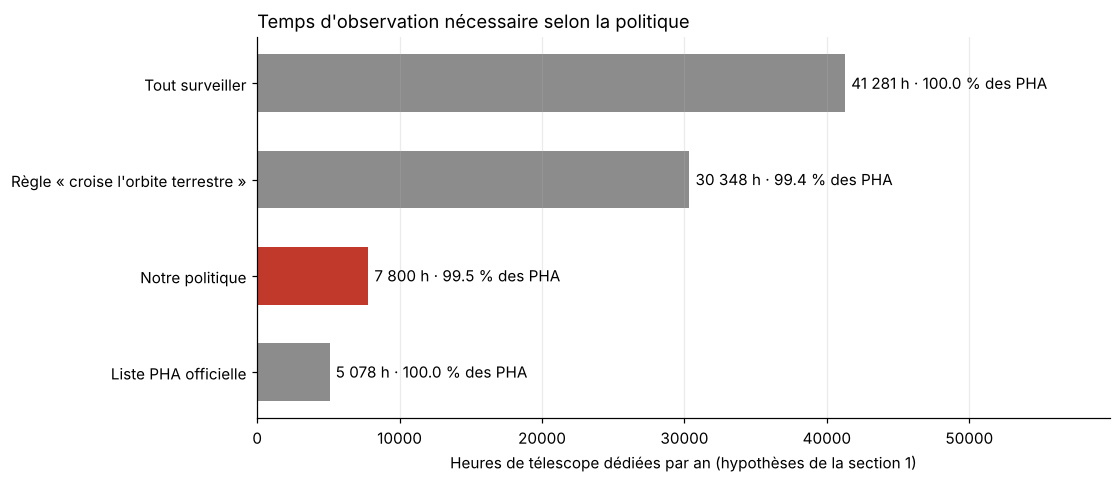

Par rapport à « Tout surveiller » : 81% d'heures en moins
Par rapport à « Règle « croise l'orbite terrestre » » : 74% d'heures en moins
Par rapport à « Liste PHA officielle » : 54% d'heures en plus


In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = policies["heures / an"].sort_values()
colors = [RED if n == "Notre politique" else GREY for n in order.index]
bars = ax.barh(order.index, order.values, color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{fmt(v)} h · {policies.loc[n, '% des PHA officiels']:.1f} % des PHA"
                           for n, v in zip(order.index, order.values)], padding=4)
ax.set_xlim(0, order.max() * 1.45)
ax.set_xlabel("Heures de télescope dédiées par an (hypothèses de la section 1)")
ax.set_title("Temps d'observation nécessaire selon la politique", loc="left")
ax.grid(axis="y", visible=False)
save(fig, "comparaison_politiques")
plt.show()

ours = policies.loc["Notre politique"]
for other in ["Tout surveiller", "Règle « croise l'orbite terrestre »", "Liste PHA officielle"]:
    delta = 1 - ours["heures / an"] / policies.loc[other, "heures / an"]
    print(f"Par rapport à « {other} » : {delta:.0%} d'heures en moins" if delta > 0 else
          f"Par rapport à « {other} » : {-delta:.0%} d'heures en plus")

**Lecture :**

- **Contre « tout surveiller » ou la règle d'expert**, la politique divise le temps de télescope nécessaire par 4 à 5, en couvrant toujours presque tous les PHA.
- **Contre la liste PHA officielle**, elle demande environ **50 % de temps en plus**. Ce n'est pas une économie mais un **meilleur usage** du temps :
  - elle ajoute plusieurs milliers d'objets qui **pourraient** dépasser 140 m mais que la liste officielle ignore, car elle suppose un albédo fixe de 0,14 ;
  - elle **concentre** l'effort : un petit nombre d'objets urgents (niveau 1) reçoit 4 observations par an, au lieu de traiter les 2 539 PHA de la même façon.

C'est l'argument à présenter à la PDCO : la valeur n'est pas de faire moins, mais de **ne rien laisser passer** et d'observer **d'abord** ce qui presse.

## 8. La file de priorité

In [13]:
tier_rank = {"Niveau 1": 0, "Niveau 2": 1, "Niveau 3": 2}
queue = (df.assign(_tier=df["niveau"].map(tier_rank),
                   _date=df["date_approche_min"].fillna(pd.Timestamp("2100-01-01")))
         .sort_values(["_tier", "_date", "energie_Mt_haute"], ascending=[True, True, False])
         .drop(columns=["_tier", "_date"]))
queue.insert(0, "rang", range(1, len(queue) + 1))

columns = ["rang", "niveau", "pdes", "full_name", "categorie_risque", "raisons",
           "diametre_km", "diametre_km_haut", "source_diametre", "moid_au",
           "approche_min_DL", "date_approche_min", "energie_Mt_haute", "proba_pha", "cluster", "pha"]
queue[columns].to_csv(PROCESSED_DIR / "file_priorite.csv", index=False)
queue[columns].head(40).to_csv(REPORT_DIR / "file_priorite_top40.csv", index=False)

show = queue[columns].head(15).copy()
show["diametre_m"] = (show.pop("diametre_km") * 1000).round(0)
show["diametre_haut_m"] = (show.pop("diametre_km_haut") * 1000).round(0)
show["date_approche_min"] = show["date_approche_min"].dt.strftime("%Y-%m-%d")
show[["rang", "niveau", "full_name", "raisons", "diametre_m", "diametre_haut_m", "moid_au",
      "approche_min_DL", "date_approche_min", "energie_Mt_haute", "proba_pha"]]

,rang,niveau,full_name,raisons,diametre_m,diametre_haut_m,moid_au,approche_min_DL,date_approche_min,energie_Mt_haute,proba_pha
4544,1,Niveau 1,(2002 TB70),PHA probable · approche à 13.4 DL,189.000,405.000,0.017,13.390,2026-04-07,"2,273.430",0.856
40733,2,Niveau 1,(2026 BK2),PHA probable · approche à 10.0 DL,216.000,461.000,0.003,10.000,2026-04-22,"3,048.181",0.783
2877,3,Niveau 1,530520 (2011 LT17),PHA probable · approche à 16.0 DL,176.000,375.000,0.004,16.010,2026-06-12,"2,979.321",0.664
40086,4,Niveau 1,(2025 WC4),PHA probable · approche à 10.2 DL · découverte...,397.000,848.000,0.014,10.150,2026-06-21,"48,889.540",0.708
561,5,Niveau 1,152637 (1997 NC1),PHA probable · approche à 6.7 DL,775.000,"1,656.000",0.015,6.670,2026-06-27,"150,681.254",0.823
2780,6,Niveau 1,523808 (2007 ML24),PHA probable · approche à 9.0 DL,436.000,931.000,0.025,9.040,2026-07-04,"53,354.382",0.846
815,7,Niveau 1,173561 (2000 YV137),PHA probable · approche à 13.1 DL,757.000,"1,618.000",0.018,13.060,2026-08-09,"266,860.327",0.773
20729,8,Niveau 1,(2019 NY2),PHA probable · approche à 6.5 DL,217.000,463.000,0.018,6.530,2026-08-10,"3,509.014",0.779
14077,9,Niveau 1,(2016 BV14),PHA probable · approche à 19.0 DL,255.000,544.000,0.007,19.020,2026-08-10,"15,578.644",0.820
10613,10,Niveau 1,(2013 QC11),PHA probable · approche à 14.4 DL,175.000,373.000,0.031,14.420,2026-08-13,"4,107.140",0.871


Le niveau 1 est trié par **date de l'approche la plus proche prévue d'ici 2035** (la plus imminente d'abord), puis par **énergie pessimiste**. Ce fichier (`data/processed/07_risk_policy/file_priorite.csv`) sera la source de données du Streamlit au jalon 3.

## Synthèse

| Seuil | Valeur | Justification |
|---|---|---|
| MOID | ≤ 0,05 UA | Définition officielle d'un PHA |
| Taille | ≥ 140 m (diamètre estimé = probable ; borne haute = possible) | Seuil de dégâts régionaux ; borne haute pour le « zéro faux négatif » |
| Approche urgente | < 20 distances lunaires d'ici 2035 | ≈ 0,05 UA, même ordre de grandeur que le seuil de MOID |
| Orbite incertaine | `condition_code` ≥ 7 | Risque de perdre la trace de l'objet |
| Découverte récente | < 1 an | MOID et taille encore peu fiables ; angle mort du modèle de l'étape 5 |
| Filet du modèle | probabilité ≥ seuil à 99 % de rappel de l'étape 5 | Rattrape les découvertes récentes au profil dangereux |

| Résultat | Valeur |
|---|---|
| Objets à observer activement (niveaux 1 et 2) | environ 14 % du catalogue (niveau 1 : moins de 2 %) |
| PHA officiels couverts | 99,5 % ; les 12 autres ont un diamètre mesuré inférieur à 140 m |
| Objets ajoutés par rapport à la liste officielle | plusieurs milliers de PHA probables ou possibles plus sombres que prévu |
| Temps de télescope | 4 à 5 fois moins que « tout surveiller » ou la règle d'expert ; environ 50 % de plus que la liste officielle, mais réparti selon l'urgence et étendu aux objets sombres |